                                    训练结果分析工具                                    

📂 分析路径: /home/ustc1958/lxy/1/MacroHFT/result/low_level/ETHUSDT/vol/pos_2/4/label_1/seed_12345
📊 配置: 使用编号文件=True, 验证集数量=2
💾 图像文件名: low_level_ETHUSDT_vol_pos_2_4_label_1_return_rate_curve.png

                               开始收集各epoch的验证结果...                               
✓  Epoch  1: 收益率 [0.45%, -0.10%] → 平均 0.17%
✓  Epoch  2: 收益率 [0.32%, -0.11%] → 平均 0.11%
✓  Epoch  3: 收益率 [-0.04%, -0.05%] → 平均 -0.05%
✓  Epoch  4: 收益率 [-0.00%, -0.45%] → 平均 -0.23%
✓  Epoch  5: 收益率 [0.09%, -0.23%] → 平均 -0.07%
✓  Epoch  6: 收益率 [0.03%, -0.50%] → 平均 -0.23%
✓  Epoch  7: 收益率 [-0.11%, -0.69%] → 平均 -0.40%
✓  Epoch  8: 收益率 [0.24%, -0.31%] → 平均 -0.03%
✓  Epoch  9: 收益率 [0.10%, -0.13%] → 平均 -0.01%
✓  Epoch 10: 收益率 [-0.44%, -0.59%] → 平均 -0.52%
✓  Epoch 11: 收益率 [-0.33%, -0.65%] → 平均 -0.49%
✓  Epoch 12: 收益率 [-0.35%, -0.46%] → 平均 -0.40%
✓  Epoch 13: 收益率 [-0.34%, -0.43%] → 平均 -0.38%
✓  Epoch 14: 收益率 [-0.26%, -0.38%] → 平均 -0.32%
✓  Epoch 1

/tmp/ipykernel_2581591/3130979570.py:253: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans Mono.
  plt.tight_layout()
/tmp/ipykernel_2581591/3130979570.py:254: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans Mono.
  plt.savefig(img_path, dpi=150, bbox_inches='tight')



✓ 图表已保存: /home/ustc1958/lxy/1/MacroHFT/tools/results/low_level_ETHUSDT_vol_pos_2_4_label_1_return_rate_curve.png


/home/ustc1958/miniconda3/envs/macrohft/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans Mono.
  fig.canvas.print_figure(bytes_io, **kw)


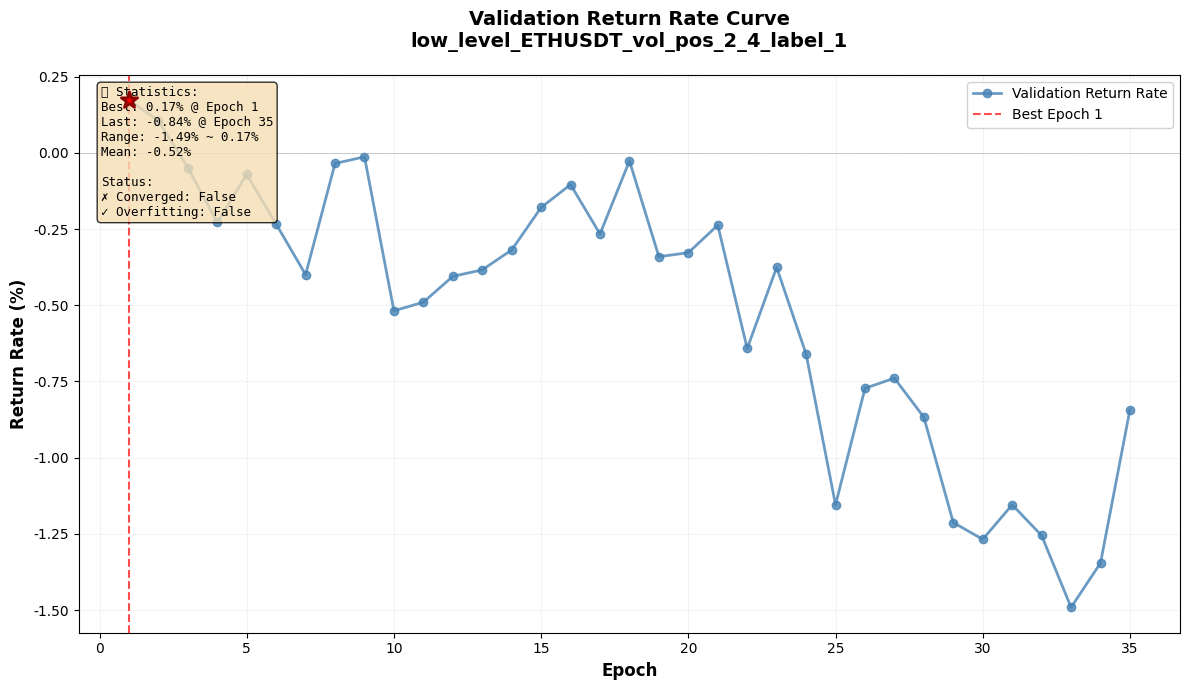


                                     分析完成!                                      


In [3]:
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

# ======================== 路径配置 ========================
# 修改下面的路径为你的实验结果目录
base = Path(r'/home/ustc1958/lxy/1/MacroHFT/result/low_level/ETHUSDT/vol/pos_2/4/label_1/seed_12345')
save = Path(r'/home/ustc1958/lxy/1/MacroHFT/tools')

# 配置：是否使用带编号的文件
USE_NUMBERED_FILES = True  # low_level: True, high_level: False
NUM_VAL_FILES = 2  # 验证集数量（通常为2个不同的初始仓位）

print("="*80)
print("训练结果分析工具".center(80))
print("="*80)
print(f"\n📂 分析路径: {base}")
print(f"📊 配置: 使用编号文件={USE_NUMBERED_FILES}, 验证集数量={NUM_VAL_FILES}")

# 检查路径是否存在
if not base.exists():
    print(f"\n❌ 错误: 路径不存在!")
    print(f"   请检查路径: {base}")
    raise SystemExit(1)

# ======================== 生成文件名 ========================
path_parts = base.parts
try:
    result_idx = path_parts.index('result')
    relevant_parts = path_parts[result_idx+1:-1]  # 排除 seed_xxxxx
    filename_base = '_'.join(relevant_parts).replace(' ', '_')
except (ValueError, IndexError):
    filename_base = '_'.join(path_parts[-6:-1]).replace(' ', '_')

print(f"💾 图像文件名: {filename_base}_return_rate_curve.png")

# ======================== 辅助函数 ========================
def load_scalar(path):
    """加载标量值 (.npy文件)"""
    arr = np.load(path, allow_pickle=True)
    try:
        return float(arr.item())
    except Exception:
        return float(np.asarray(arr).ravel()[0])

# ======================== 收集 Epoch 指标 ========================
print("\n" + "="*80)
print("开始收集各epoch的验证结果...".center(80))
print("="*80)

vals = []
epoch_details = []

for ep in sorted(base.glob('epoch_*'), key=lambda p: int(p.name.split('_')[1])):
    try:
        ep_num = int(ep.name.split('_')[1])
    except Exception:
        continue
    
    vdir = ep / 'val'
    if not vdir.exists():
        print(f"⚠️  Epoch {ep_num:2d}: 跳过 (val目录不存在)")
        continue
    
    # 直接读取已保存的 return_rate_mean_val 文件
    if USE_NUMBERED_FILES:
        all_returns = []
        
        for i in range(NUM_VAL_FILES):
            return_rate_path = vdir / f'return_rate_mean_val_{i}.npy'
            
            if not return_rate_path.exists():
                continue
            
            try:
                # 读取收益率 (注意: 这是比值, 如 0.05 = 5%)
                return_rate = load_scalar(return_rate_path)
                all_returns.append(return_rate)
            except Exception as e:
                print(f"⚠️  Epoch {ep_num:2d} 验证集{i}: 读取失败 ({e})")
                continue
        
        if all_returns:
            avg_return = float(np.mean(all_returns))
            vals.append((ep_num, avg_return))
            epoch_details.append({
                "epoch": ep_num,
                "return_rate": avg_return,
                "individual_returns": all_returns
            })
            
            # 打印详细信息
            returns_str = ", ".join([f"{r*100:.2f}%" for r in all_returns])
            print(f"✓  Epoch {ep_num:2d}: 收益率 [{returns_str}] → 平均 {avg_return*100:.2f}%")
        else:
            print(f"⚠️  Epoch {ep_num:2d}: 跳过 (无有效验证文件)")
    else:
        # high_level 模式
        return_rate_path = vdir / 'return_rate_mean_val.npy'
        
        if not return_rate_path.exists():
            print(f"⚠️  Epoch {ep_num:2d}: 跳过 (文件不存在)")
            continue
        
        try:
            return_rate = load_scalar(return_rate_path)
            vals.append((ep_num, return_rate))
            epoch_details.append({"epoch": ep_num, "return_rate": return_rate})
            print(f"✓  Epoch {ep_num:2d}: 收益率 {return_rate*100:.2f}%")
        except Exception as e:
            print(f"⚠️  Epoch {ep_num:2d}: 读取失败 ({e})")

# 检查是否收集到数据
if not vals:
    print("\n" + "="*80)
    print("❌ 错误: 未找到任何验证数据!".center(80))
    print("="*80)
    print("\n请检查:")
    print(f"  1. 路径是否正确: {base}")
    print(f"  2. USE_NUMBERED_FILES = {USE_NUMBERED_FILES}")
    print(f"  3. NUM_VAL_FILES = {NUM_VAL_FILES}")
    print(f"  4. 是否存在 return_rate_mean_val_*.npy 文件")
    raise SystemExit(2)

# ======================== 计算诊断指标 ========================
print("\n" + "="*80)
print("计算统计指标...".center(80))
print("="*80)

vals_sorted = sorted(vals, key=lambda x: x[0])
epochs = [e for e, _ in vals_sorted]
returns = np.array([r for _, r in vals_sorted], dtype=float)

best_idx = int(np.argmax(returns))
best_epoch = epochs[best_idx]
best_return = float(returns[best_idx])
last_return = float(returns[-1])
last_epoch = int(epochs[-1])

# 收敛判断: 最后N个epoch的波动幅度
N = min(5, len(returns))
conv_tol = 0.005  # 0.5% 的波动容忍度
converged = False
if len(returns) >= N:
    window = returns[-N:]
    window_range = float(window.max() - window.min())
    converged = window_range < conv_tol
    print(f"\n📊 收敛性分析 (最后{N}个epoch):")
    print(f"   波动幅度: {window_range*100:.3f}%")
    print(f"   容忍阈值: {conv_tol*100:.3f}%")
    print(f"   是否收敛: {'✓ 是' if converged else '✗ 否'}")

# 过拟合判断: 最后的收益率明显低于最佳值
margin = 0.01  # 1% 下降幅度
recent = returns[-N:] if len(returns) >= N else returns
non_increasing = bool(np.all(np.diff(recent) <= 1e-6)) if len(recent) > 1 else False
overfit = (last_return < (best_return - margin)) and non_increasing

print(f"\n📉 过拟合分析:")
print(f"   最佳收益率: {best_return*100:.2f}% @ Epoch {best_epoch}")
print(f"   最后收益率: {last_return*100:.2f}% @ Epoch {last_epoch}")
print(f"   下降幅度: {(last_return - best_return)*100:.2f}%")
print(f"   是否过拟合: {'✓ 是' if overfit else '✗ 否'}")

# 汇总统计
summary = {
    "epochs": epochs,
    "return_rates_pct": [float(x*100) for x in returns.tolist()],  # 转为百分比
    "best_epoch": best_epoch,
    "best_return_pct": best_return * 100,
    "last_epoch": last_epoch,
    "last_return_pct": last_return * 100,
    "delta_pct": float((last_return - best_return) * 100),
    "converged": converged,
    "overfit": overfit,
}

print("\n" + "="*80)
print("训练摘要".center(80))
print("="*80)
print(f"\n总Epoch数: {len(epochs)}")
print(f"收益率范围: {returns.min()*100:.2f}% ~ {returns.max()*100:.2f}%")
print(f"平均收益率: {returns.mean()*100:.2f}%")
print(f"标准差: {returns.std()*100:.3f}%")
print(f"\n最佳模型: Epoch {best_epoch} ({best_return*100:.2f}%)")
print(f"最后模型: Epoch {last_epoch} ({last_return*100:.2f}%)")
print(f"状态: {'收敛' if converged else '未收敛'}, {'过拟合' if overfit else '正常'}")

# ======================== 可视化部分 ========================
print("\n" + "="*80)
print("生成可视化图表...".center(80))
print("="*80)

# 转换为百分比
returns_pct = returns * 100
best_return_pct = best_return * 100
last_return_pct = last_return * 100

# 设置中文字体支持
plt.rcParams['font.sans-serif'] = ['SimHei', 'Arial Unicode MS', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

fig, ax = plt.subplots(figsize=(12, 7))

# 绘制收益率曲线
ax.plot(epochs, returns_pct, label='Validation Return Rate', marker='o', 
        linewidth=2, markersize=6, color='steelblue', alpha=0.8)

# 标注最佳点
ax.axvline(best_epoch, color='red', linestyle='--', linewidth=1.5, 
           label=f'Best Epoch {best_epoch}', alpha=0.7)
ax.scatter([best_epoch], [best_return_pct], color='red', s=150, 
           zorder=5, marker='*', edgecolors='darkred', linewidths=2)

# 添加零线
ax.axhline(0, color='gray', linestyle='-', linewidth=0.5, alpha=0.5)

# 图表标题和标签
title = f'Validation Return Rate Curve\n{filename_base}'
ax.set_title(title, fontsize=14, fontweight='bold', pad=20)
ax.set_xlabel('Epoch', fontsize=12, fontweight='bold')
ax.set_ylabel('Return Rate (%)', fontsize=12, fontweight='bold')

# 网格
ax.grid(True, alpha=0.3, linestyle='--', linewidth=0.5)

# 图例
ax.legend(loc='best', fontsize=10, framealpha=0.9)

# 信息框
info_text = (
    f"📊 Statistics:\n"
    f"Best: {best_return_pct:.2f}% @ Epoch {best_epoch}\n"
    f"Last: {last_return_pct:.2f}% @ Epoch {last_epoch}\n"
    f"Range: {returns_pct.min():.2f}% ~ {returns_pct.max():.2f}%\n"
    f"Mean: {returns_pct.mean():.2f}%\n\n"
    f"Status:\n"
    f"{'✓' if converged else '✗'} Converged: {converged}\n"
    f"{'✓' if not overfit else '✗'} Overfitting: {overfit}"
)

ax.text(0.02, 0.98, info_text, transform=ax.transAxes, 
        fontsize=9, verticalalignment='top',
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8),
        family='monospace')

# 保存图片
save_dir = save / 'results'
save_dir.mkdir(parents=True, exist_ok=True)
img_path = save_dir / f'{filename_base}_return_rate_curve.png'

plt.tight_layout()
plt.savefig(img_path, dpi=150, bbox_inches='tight')
print(f"\n✓ 图表已保存: {img_path}")

plt.show()
plt.close()

print("\n" + "="*80)
print("分析完成!".center(80))
print("="*80)

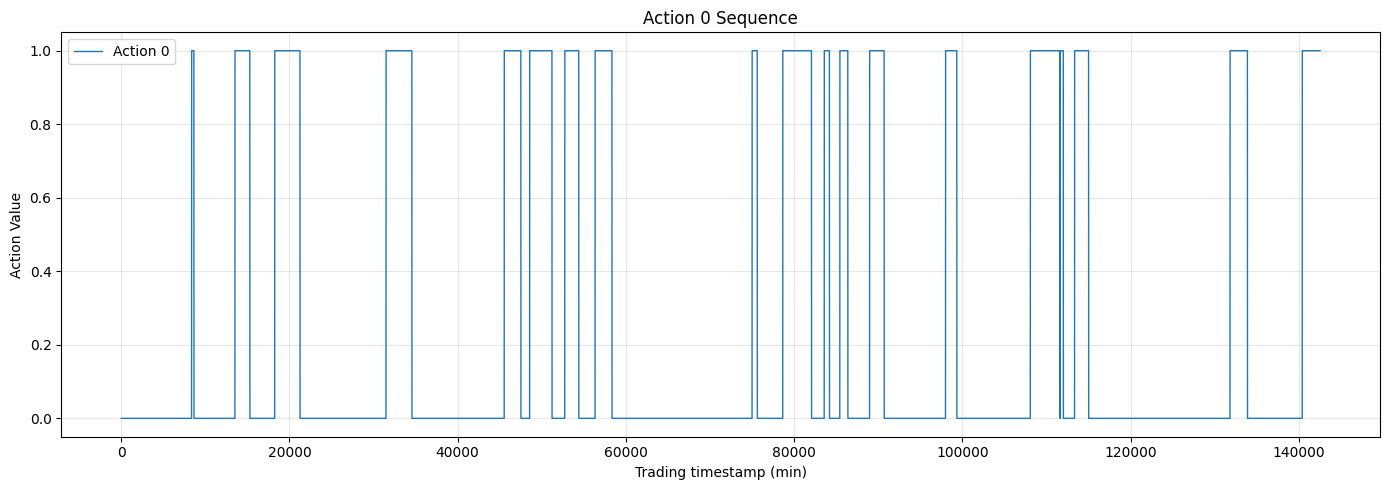

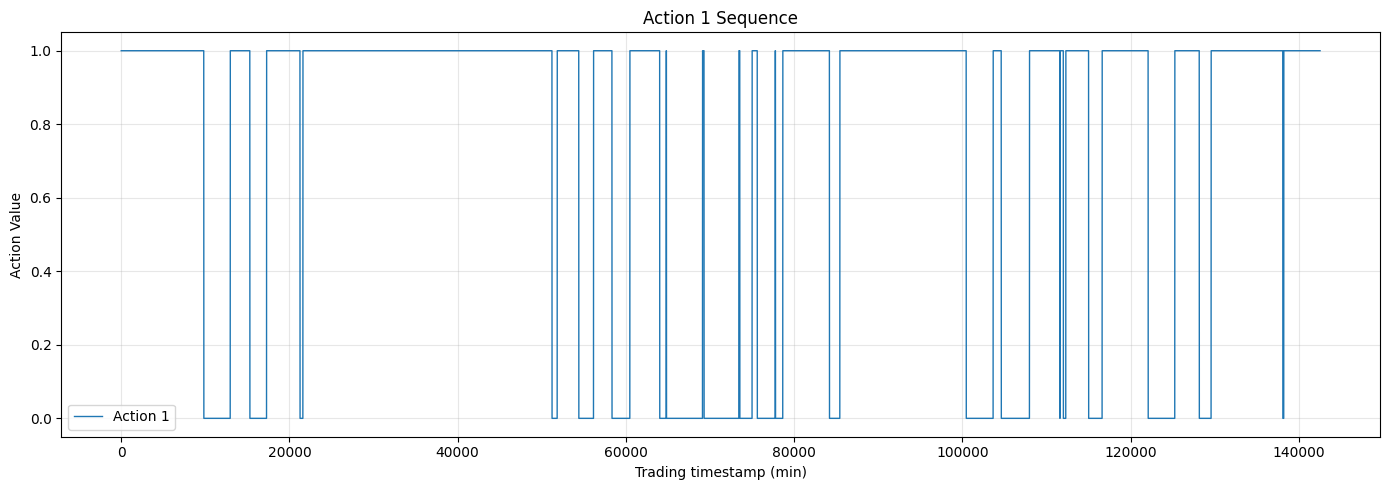

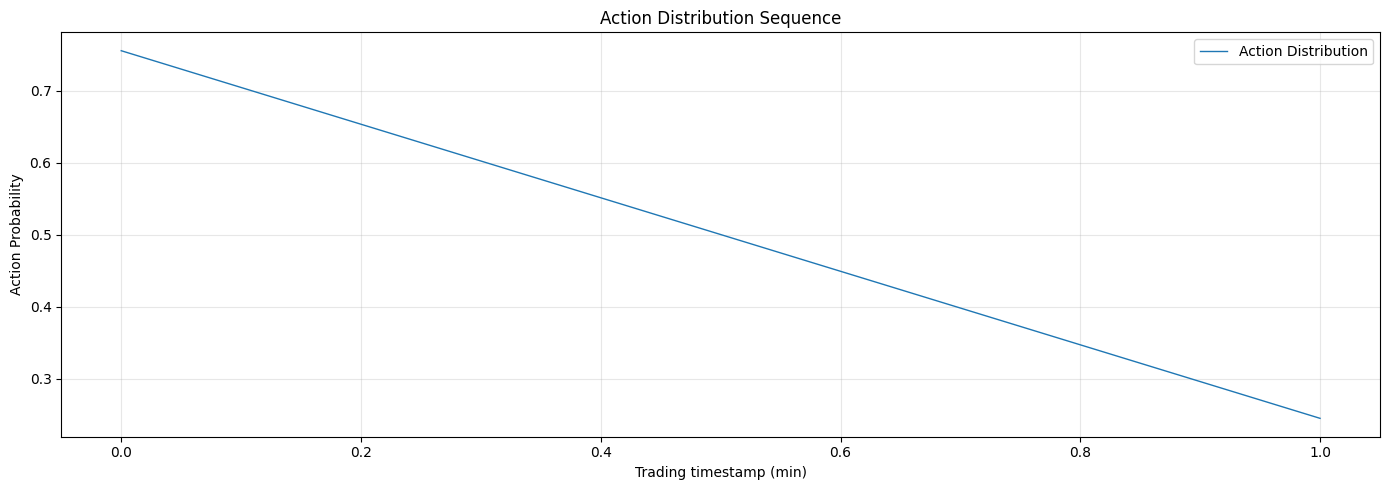

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# 路径变量，只需修改 base_path 即可
# base = '/home/ustc1958/lxy/1/MacroHFT/result/low_level/ETHUSDT/reward30000/slope/pos_2/4/label_2/seed_12345/epoch_3/val'
base = '/home/ustc1958/lxy/1/MacroHFT/result/low_level/ETHUSDT/vol/pos_2/4/label_1/seed_12345/epoch_1/val'
paths = [f'{base}/action_val_0.npy', f'{base}/action_val_1.npy']
labels = ['Action 0', 'Action 1']

for p, label in zip(paths, labels):
    arr = np.load(p, allow_pickle=True)
    if getattr(arr, 'dtype', None) == object:
        try:
            arr = np.concatenate(arr)
        except Exception:
            arr = np.array(list(arr), dtype=np.float64)
    arr = np.asarray(arr, dtype=np.float64).ravel()
    plt.figure(figsize=(14, 5))
    plt.plot(arr, label=label, linewidth=1)
    plt.title(f'{label} Sequence')
    plt.xlabel('Trading timestamp (min)')
    plt.ylabel('Action Value')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

# 可视化 action_distribution_val_0.npy 文件内容
dist_path = '/home/ustc1958/lxy/1/MacroHFT/result/low_level/ETHUSDT/vol/pos_2/4/label_1/seed_12345/epoch_1/val/action_distribution_val_0.npy'
dist_arr = np.load(dist_path, allow_pickle=True)
if getattr(dist_arr, 'dtype', None) == object:
    try:
        dist_arr = np.concatenate(dist_arr)
    except Exception:
        dist_arr = np.array(list(dist_arr), dtype=np.float64)
dist_arr = np.asarray(dist_arr, dtype=np.float64)

plt.figure(figsize=(14, 5))
if dist_arr.ndim == 2:
    for i in range(dist_arr.shape[1]):
        plt.plot(dist_arr[:, i], label=f'Action {i}', linewidth=1)
    plt.title('Action Distribution Sequence Comparison')
    plt.xlabel('Trading timestamp (min)')
    plt.ylabel('Action Probability')
    plt.legend()
else:
    plt.plot(dist_arr, label='Action Distribution', linewidth=1)
    plt.title('Action Distribution Sequence')
    plt.xlabel('Trading timestamp (min)')
    plt.ylabel('Action Probability')
    plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

                                    训练结果分析工具                                    

📂 分析路径: /home/ustc1958/lxy/1/MacroHFT/result/low_level/ETHUSDT/reward1000/slope/pos_2/4/label_2/seed_12345
📊 配置: 使用编号文件=True, 验证集数量=2
💾 图像文件名: low_level_ETHUSDT_reward1000_slope_pos_2_4_label_2_return_rate_curve.png

                               开始收集各epoch的验证结果...                               
✓  Epoch  1: 收益率 [-0.22%, 0.18%] → 平均 -0.02%
✓  Epoch  2: 收益率 [0.50%, 0.76%] → 平均 0.63%
✓  Epoch  3: 收益率 [0.73%, 0.97%] → 平均 0.85%
✓  Epoch  4: 收益率 [0.17%, 0.51%] → 平均 0.34%
✓  Epoch  5: 收益率 [0.15%, 0.52%] → 平均 0.33%

                                   计算统计指标...                                    

📊 收敛性分析 (最后5个epoch):
   波动幅度: 0.869%
   容忍阈值: 0.500%
   是否收敛: ✗ 否

📉 过拟合分析:
   最佳收益率: 0.85% @ Epoch 3
   最后收益率: 0.33% @ Epoch 5
   下降幅度: -0.51%
   是否过拟合: ✗ 否

                                      训练摘要                                      

总Epoch数: 5
收益率范围: -0.02% ~ 0.85%
平均收益率: 0.43%
标准差: 0.295%

最佳模型: Epoch 3 (0.85%

/tmp/ipykernel_2599623/704514748.py:253: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans Mono.
  plt.tight_layout()
/tmp/ipykernel_2599623/704514748.py:254: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans Mono.
  plt.savefig(img_path, dpi=150, bbox_inches='tight')



✓ 图表已保存: /home/ustc1958/lxy/1/MacroHFT/tools/results/low_level_ETHUSDT_reward1000_slope_pos_2_4_label_2_return_rate_curve.png


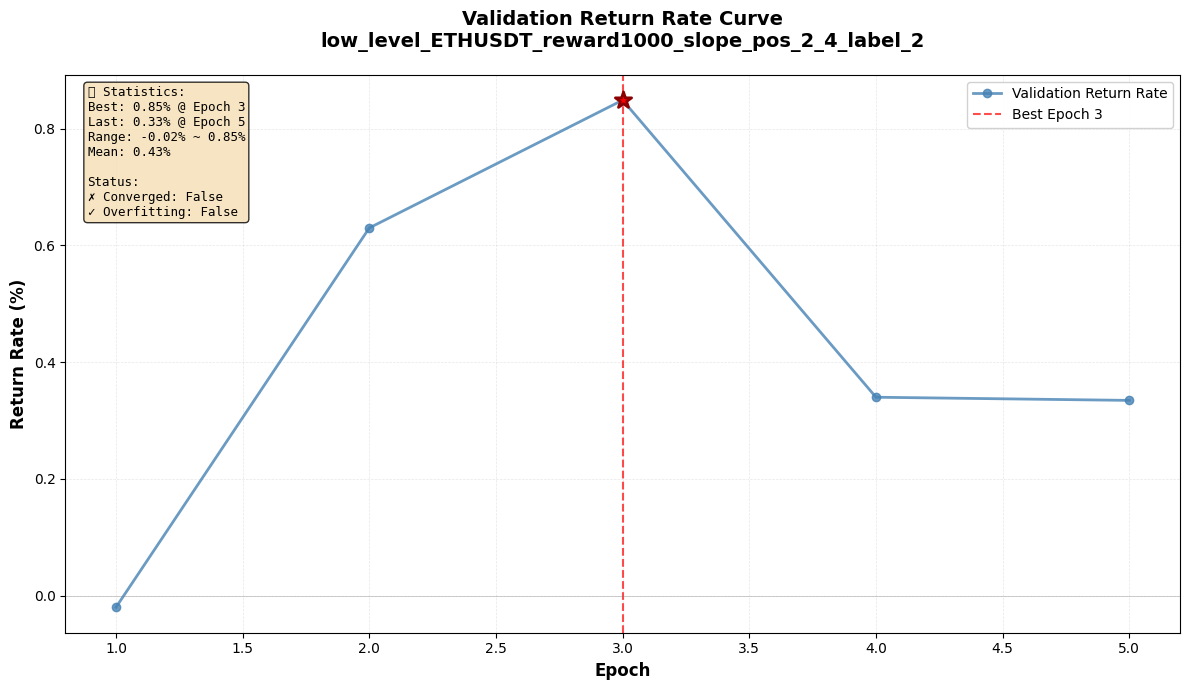


                                     分析完成!                                      


In [ ]:
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

# ======================== 路径配置 ========================
# 修改下面的路径为你的实验结果目录
base = Path(r'/home/ustc1958/lxy/1/MacroHFT/result/low_level/ETHUSDT/slope/pos_2/4/label_2/seed_12345')
base = Path(r'/home/ustc1958/lxy/1/MacroHFT/result/low_level/ETHUSDT/reward1/slope/pos_2/4/label_2/seed_12345')
base = Path(r'/home/ustc1958/lxy/1/MacroHFT/result/low_level/ETHUSDT/reward1000/slope/pos_2/4/label_2/seed_12345')
base = Path(r'/home/ustc1958/lxy/1/MacroHFT/result/low_level/ETHUSDT/reward30000/slope/pos_2/4/label_2/seed_12345')
save = Path(r'/home/ustc1958/lxy/1/MacroHFT/tools')

# 配置：是否使用带编号的文件
USE_NUMBERED_FILES = True  # low_level: True, high_level: False
NUM_VAL_FILES = 2  # 验证集数量（通常为2个不同的初始仓位）

print("="*80)
print("训练结果分析工具".center(80))
print("="*80)
print(f"\n📂 分析路径: {base}")
print(f"📊 配置: 使用编号文件={USE_NUMBERED_FILES}, 验证集数量={NUM_VAL_FILES}")

# 检查路径是否存在
if not base.exists():
    print(f"\n❌ 错误: 路径不存在!")
    print(f"   请检查路径: {base}")
    raise SystemExit(1)

# ======================== 生成文件名 ========================
path_parts = base.parts
try:
    result_idx = path_parts.index('result')
    relevant_parts = path_parts[result_idx+1:-1]  # 排除 seed_xxxxx
    filename_base = '_'.join(relevant_parts).replace(' ', '_')
except (ValueError, IndexError):
    filename_base = '_'.join(path_parts[-6:-1]).replace(' ', '_')

print(f"💾 图像文件名: {filename_base}_return_rate_curve.png")

# ======================== 辅助函数 ========================
def load_scalar(path):
    """加载标量值 (.npy文件)"""
    arr = np.load(path, allow_pickle=True)
    try:
        return float(arr.item())
    except Exception:
        return float(np.asarray(arr).ravel()[0])

# ======================== 收集 Epoch 指标 ========================
print("\n" + "="*80)
print("开始收集各epoch的验证结果...".center(80))
print("="*80)

vals = []
epoch_details = []

for ep in sorted(base.glob('epoch_*'), key=lambda p: int(p.name.split('_')[1])):
    try:
        ep_num = int(ep.name.split('_')[1])
    except Exception:
        continue
    
    vdir = ep / 'val'
    if not vdir.exists():
        print(f"⚠️  Epoch {ep_num:2d}: 跳过 (val目录不存在)")
        continue
    
    # 直接读取已保存的 return_rate_mean_val 文件
    if USE_NUMBERED_FILES:
        all_returns = []
        
        for i in range(NUM_VAL_FILES):
            return_rate_path = vdir / f'return_rate_mean_val_{i}.npy'
            
            if not return_rate_path.exists():
                continue
            
            try:
                # 读取收益率 (注意: 这是比值, 如 0.05 = 5%)
                return_rate = load_scalar(return_rate_path)
                all_returns.append(return_rate)
            except Exception as e:
                print(f"⚠️  Epoch {ep_num:2d} 验证集{i}: 读取失败 ({e})")
                continue
        
        if all_returns:
            avg_return = float(np.mean(all_returns))
            vals.append((ep_num, avg_return))
            epoch_details.append({
                "epoch": ep_num,
                "return_rate": avg_return,
                "individual_returns": all_returns
            })
            
            # 打印详细信息
            returns_str = ", ".join([f"{r*100:.2f}%" for r in all_returns])
            print(f"✓  Epoch {ep_num:2d}: 收益率 [{returns_str}] → 平均 {avg_return*100:.2f}%")
        else:
            print(f"⚠️  Epoch {ep_num:2d}: 跳过 (无有效验证文件)")
    else:
        # high_level 模式
        return_rate_path = vdir / 'return_rate_mean_val.npy'
        
        if not return_rate_path.exists():
            print(f"⚠️  Epoch {ep_num:2d}: 跳过 (文件不存在)")
            continue
        
        try:
            return_rate = load_scalar(return_rate_path)
            vals.append((ep_num, return_rate))
            epoch_details.append({"epoch": ep_num, "return_rate": return_rate})
            print(f"✓  Epoch {ep_num:2d}: 收益率 {return_rate*100:.2f}%")
        except Exception as e:
            print(f"⚠️  Epoch {ep_num:2d}: 读取失败 ({e})")

# 检查是否收集到数据
if not vals:
    print("\n" + "="*80)
    print("❌ 错误: 未找到任何验证数据!".center(80))
    print("="*80)
    print("\n请检查:")
    print(f"  1. 路径是否正确: {base}")
    print(f"  2. USE_NUMBERED_FILES = {USE_NUMBERED_FILES}")
    print(f"  3. NUM_VAL_FILES = {NUM_VAL_FILES}")
    print(f"  4. 是否存在 return_rate_mean_val_*.npy 文件")
    raise SystemExit(2)

# ======================== 计算诊断指标 ========================
print("\n" + "="*80)
print("计算统计指标...".center(80))
print("="*80)

vals_sorted = sorted(vals, key=lambda x: x[0])
epochs = [e for e, _ in vals_sorted]
returns = np.array([r for _, r in vals_sorted], dtype=float)

best_idx = int(np.argmax(returns))
best_epoch = epochs[best_idx]
best_return = float(returns[best_idx])
last_return = float(returns[-1])
last_epoch = int(epochs[-1])

# 收敛判断: 最后N个epoch的波动幅度
N = min(5, len(returns))
conv_tol = 0.005  # 0.5% 的波动容忍度
converged = False
if len(returns) >= N:
    window = returns[-N:]
    window_range = float(window.max() - window.min())
    converged = window_range < conv_tol
    print(f"\n📊 收敛性分析 (最后{N}个epoch):")
    print(f"   波动幅度: {window_range*100:.3f}%")
    print(f"   容忍阈值: {conv_tol*100:.3f}%")
    print(f"   是否收敛: {'✓ 是' if converged else '✗ 否'}")

# 过拟合判断: 最后的收益率明显低于最佳值
margin = 0.01  # 1% 下降幅度
recent = returns[-N:] if len(returns) >= N else returns
non_increasing = bool(np.all(np.diff(recent) <= 1e-6)) if len(recent) > 1 else False
overfit = (last_return < (best_return - margin)) and non_increasing

print(f"\n📉 过拟合分析:")
print(f"   最佳收益率: {best_return*100:.2f}% @ Epoch {best_epoch}")
print(f"   最后收益率: {last_return*100:.2f}% @ Epoch {last_epoch}")
print(f"   下降幅度: {(last_return - best_return)*100:.2f}%")
print(f"   是否过拟合: {'✓ 是' if overfit else '✗ 否'}")

# 汇总统计
summary = {
    "epochs": epochs,
    "return_rates_pct": [float(x*100) for x in returns.tolist()],  # 转为百分比
    "best_epoch": best_epoch,
    "best_return_pct": best_return * 100,
    "last_epoch": last_epoch,
    "last_return_pct": last_return * 100,
    "delta_pct": float((last_return - best_return) * 100),
    "converged": converged,
    "overfit": overfit,
}

print("\n" + "="*80)
print("训练摘要".center(80))
print("="*80)
print(f"\n总Epoch数: {len(epochs)}")
print(f"收益率范围: {returns.min()*100:.2f}% ~ {returns.max()*100:.2f}%")
print(f"平均收益率: {returns.mean()*100:.2f}%")
print(f"标准差: {returns.std()*100:.3f}%")
print(f"\n最佳模型: Epoch {best_epoch} ({best_return*100:.2f}%)")
print(f"最后模型: Epoch {last_epoch} ({last_return*100:.2f}%)")
print(f"状态: {'收敛' if converged else '未收敛'}, {'过拟合' if overfit else '正常'}")

# ======================== 可视化部分 ========================
print("\n" + "="*80)
print("生成可视化图表...".center(80))
print("="*80)

# 转换为百分比
returns_pct = returns * 100
best_return_pct = best_return * 100
last_return_pct = last_return * 100

# 设置中文字体支持
plt.rcParams['font.sans-serif'] = ['SimHei', 'Arial Unicode MS', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

fig, ax = plt.subplots(figsize=(12, 7))

# 绘制收益率曲线
ax.plot(epochs, returns_pct, label='Validation Return Rate', marker='o', 
        linewidth=2, markersize=6, color='steelblue', alpha=0.8)

# 标注最佳点
ax.axvline(best_epoch, color='red', linestyle='--', linewidth=1.5, 
           label=f'Best Epoch {best_epoch}', alpha=0.7)
ax.scatter([best_epoch], [best_return_pct], color='red', s=150, 
           zorder=5, marker='*', edgecolors='darkred', linewidths=2)

# 添加零线
ax.axhline(0, color='gray', linestyle='-', linewidth=0.5, alpha=0.5)

# 图表标题和标签
title = f'Validation Return Rate Curve\n{filename_base}'
ax.set_title(title, fontsize=14, fontweight='bold', pad=20)
ax.set_xlabel('Epoch', fontsize=12, fontweight='bold')
ax.set_ylabel('Return Rate (%)', fontsize=12, fontweight='bold')

# 网格
ax.grid(True, alpha=0.3, linestyle='--', linewidth=0.5)

# 图例
ax.legend(loc='best', fontsize=10, framealpha=0.9)

# 信息框
info_text = (
    f"📊 Statistics:\n"
    f"Best: {best_return_pct:.2f}% @ Epoch {best_epoch}\n"
    f"Last: {last_return_pct:.2f}% @ Epoch {last_epoch}\n"
    f"Range: {returns_pct.min():.2f}% ~ {returns_pct.max():.2f}%\n"
    f"Mean: {returns_pct.mean():.2f}%\n\n"
    f"Status:\n"
    f"{'✓' if converged else '✗'} Converged: {converged}\n"
    f"{'✓' if not overfit else '✗'} Overfitting: {overfit}"
)

ax.text(0.02, 0.98, info_text, transform=ax.transAxes, 
        fontsize=9, verticalalignment='top',
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8),
        family='monospace')

# 保存图片
save_dir = save / 'results'
save_dir.mkdir(parents=True, exist_ok=True)
img_path = save_dir / f'{filename_base}_return_rate_curve.png'

plt.tight_layout()
plt.savefig(img_path, dpi=150, bbox_inches='tight')
print(f"\n✓ 图表已保存: {img_path}")

plt.show()
plt.close()

print("\n" + "="*80)
print("分析完成!".center(80))
print("="*80)

                 Training Result Comparison Tool (Four Curves)                  

🔍 Checking Group 1: slope (epochs)
   Path: /home/ustc1958/lxy/1/MacroHFT/result/low_level/ETHUSDT/slope/pos_2/4/label_2/seed_12345
   Found Epochs: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35]
   Total Epochs: 35

🔍 Checking Group 2: reward=1 (epochs)
   Path: /home/ustc1958/lxy/1/MacroHFT/result/low_level/ETHUSDT/reward1/slope/pos_2/4/label_2/seed_12345
   Found Epochs: [1, 2, 3, 4, 5]
   Total Epochs: 5

🔍 Checking Group 3: reward=1000 (epochs)
   Path: /home/ustc1958/lxy/1/MacroHFT/result/low_level/ETHUSDT/reward1000/slope/pos_2/4/label_2/seed_12345
   Found Epochs: [1, 2, 3, 4, 5]
   Total Epochs: 5

🔍 Checking Group 4: reward=30000 (epochs)
   Path: /home/ustc1958/lxy/1/MacroHFT/result/low_level/ETHUSDT/reward30000epo35/slope/pos_2/4/label_2/seed_12345
   Found Epochs: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 1

/tmp/ipykernel_2603014/1319238571.py:237: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans Mono.
  plt.tight_layout()
/tmp/ipykernel_2603014/1319238571.py:238: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans Mono.
  plt.savefig(img_path, dpi=300, bbox_inches='tight')



✅ Four-group plot saved to: /home/ustc1958/lxy/1/MacroHFT/tools/results/reward_comparison_four.png
✅ Plotted 4 groups (check logs for valid data)


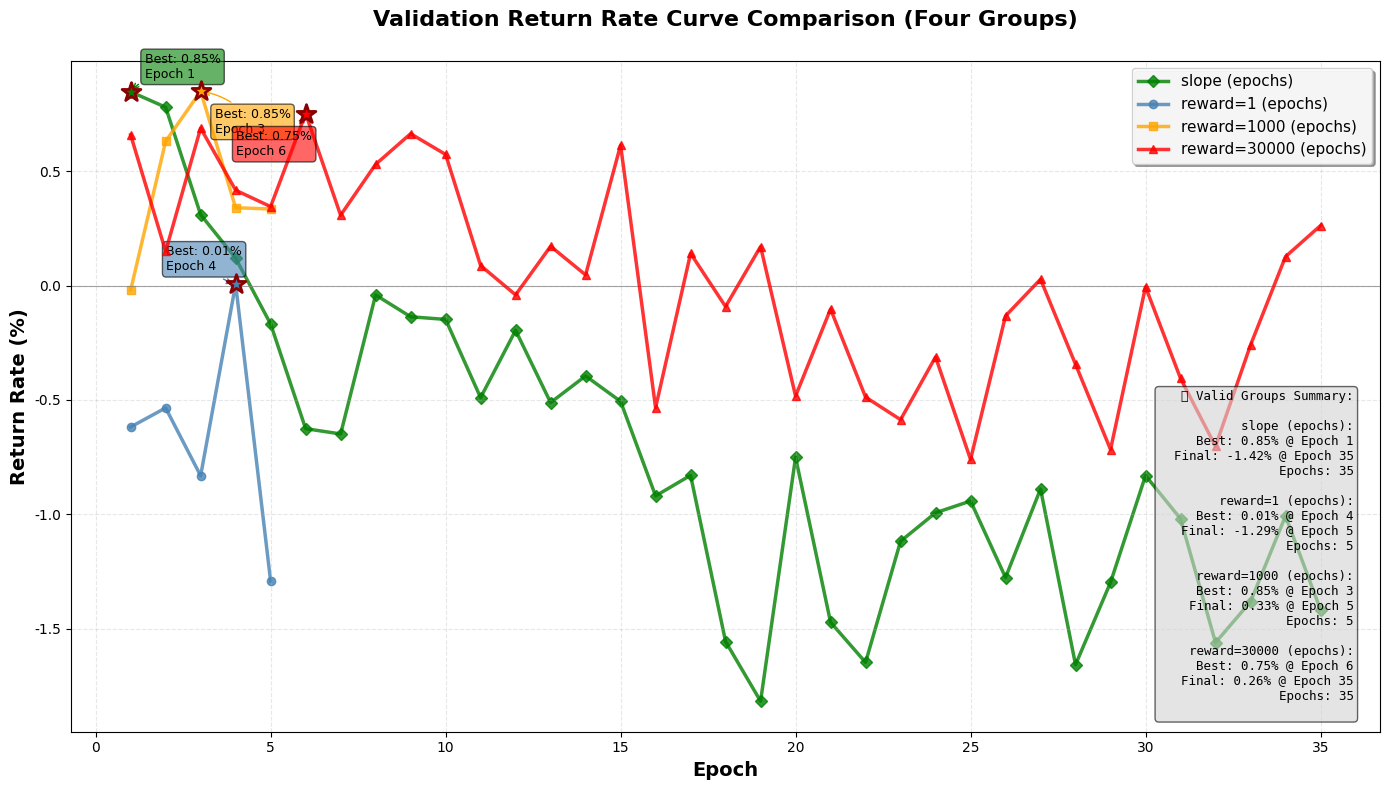


                   Four-group comparison analysis completed!                    


In [5]:
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

# ======================== Core Configuration: Four Comparison Groups ========================
base_configs = [
    {
        "path": Path(r'/home/ustc1958/lxy/1/MacroHFT/result/low_level/ETHUSDT/slope/pos_2/4/label_2/seed_12345'),
        "label": "slope (epochs)",
        "color": "green",
        "marker": "D"
    },
    {
        "path": Path(r'/home/ustc1958/lxy/1/MacroHFT/result/low_level/ETHUSDT/reward1/slope/pos_2/4/label_2/seed_12345'),
        "label": "reward=1 (epochs)",
        "color": "steelblue",
        "marker": "o"
    },
    {
        "path": Path(r'/home/ustc1958/lxy/1/MacroHFT/result/low_level/ETHUSDT/reward1000/slope/pos_2/4/label_2/seed_12345'),
        "label": "reward=1000 (epochs)",
        "color": "orange",
        "marker": "s"
    },
    {
        "path": Path(r'/home/ustc1958/lxy/1/MacroHFT/result/low_level/ETHUSDT/reward30000epo35/slope/pos_2/4/label_2/seed_12345'),
        "label": "reward=30000 (epochs)",
        "color": "red",
        "marker": "^"
    }
]

save = Path(r'/home/ustc1958/lxy/1/MacroHFT/tools')

# Common Configuration
USE_NUMBERED_FILES = True
NUM_VAL_FILES = 2
N_CONVERGE = 5
conv_tol = 0.005
overfit_margin = 0.01

print("="*80)
print("Training Result Comparison Tool (Four Curves)".center(80))
print("="*80)

# ======================== Enhanced Path & Data Check ========================
for idx, config in enumerate(base_configs):
    path = config["path"]
    label = config["label"]
    print(f"\n🔍 Checking Group {idx+1}: {label}")
    print(f"   Path: {path}")
    if not path.exists():
        print(f"   ❌ Error: Path does not exist!")
        continue
    epoch_dirs = sorted(path.glob('epoch_*'), key=lambda p: int(p.name.split('_')[1]) if p.name.split('_')[1].isdigit() else -1)
    epoch_nums = [int(d.name.split('_')[1]) for d in epoch_dirs if d.name.split('_')[1].isdigit()]
    print(f"   Found Epochs: {epoch_nums}")
    print(f"   Total Epochs: {len(epoch_nums)}")
    if label.startswith('reward=30000') and len(epoch_nums) < 35:
        print(f"   ⚠️  Warning: reward=30000组实际epoch数量为{len(epoch_nums)}，应为35，请检查数据目录！")
    if not epoch_dirs:
        print(f"   ❌ No epoch directories found!")
        continue

# ======================== Helper Functions ========================
def load_scalar(path):
    try:
        arr = np.load(path, allow_pickle=True)
        if arr.ndim == 0:
            return float(arr.item())
        elif arr.size > 0:
            return float(arr.ravel()[0])
        else:
            print(f"   ⚠️  Empty array in {path}")
            return np.nan
    except Exception as e:
        print(f"   ⚠️  Load failed for {path}: {str(e)[:50]}")
        return np.nan

def get_filename_base(path):
    path_parts = path.parts
    try:
        result_idx = path_parts.index('result')
        relevant_parts = path_parts[result_idx+1:-1]
        return '_'.join(relevant_parts).replace(' ', '_')
    except (ValueError, IndexError):
        return '_'.join(path_parts[-6:-1]).replace(' ', '_')

# ======================== Batch Collect Data ========================
print("\n" + "="*80)
print("Collecting validation results (with debug logs)...".center(80))
print("="*80)

all_results = []
for config in base_configs:
    base = config["path"]
    label = config["label"]
    color = config["color"]
    marker = config["marker"]
    print(f"\n📥 Processing {label}")
    vals = []
    epoch_dirs = sorted(
        [d for d in base.glob('epoch_*') if d.name.split('_')[1].isdigit()],
        key=lambda p: int(p.name.split('_')[1])
    )
    epoch_nums = [int(d.name.split('_')[1]) for d in epoch_dirs if d.name.split('_')[1].isdigit()]
    print(f"   Epochs to plot: {epoch_nums}")
    for ep_dir in epoch_dirs:
        ep_num = int(ep_dir.name.split('_')[1])
        vdir = ep_dir / 'val'
        if not vdir.exists():
            print(f"   ⚠️  Epoch {ep_num}: No val directory")
            continue
        all_returns = []
        for i in range(NUM_VAL_FILES):
            return_path = vdir / f'return_rate_mean_val_{i}.npy'
            if not return_path.exists():
                print(f"   ⚠️  Epoch {ep_num}: Val file {i} not found")
                continue
            return_val = load_scalar(return_path)
            if not np.isnan(return_val):
                all_returns.append(return_val)
        if all_returns:
            avg_return = np.mean(all_returns)
            vals.append((ep_num, avg_return))
            print(f"   ✅ Epoch {ep_num}: Returns {[f'{r*100:.2f}%' for r in all_returns]} → Avg {avg_return*100:.2f}%")
        else:
            print(f"   ⚠️  Epoch {ep_num}: No valid returns")
    if not vals:
        print(f"   ❌ Warning: No valid data for {label} (skipped)")
        continue
    vals_sorted = sorted(vals, key=lambda x: x[0])
    epochs = [e for e, _ in vals_sorted]
    returns = np.array([r for _, r in vals_sorted], dtype=float)
    best_idx = np.argmax(returns)
    best_epoch = epochs[best_idx]
    best_return = returns[best_idx]
    last_return = returns[-1]
    last_epoch = epochs[-1]
    converged = len(returns) >= N_CONVERGE and (returns[-N_CONVERGE:].max() - returns[-N_CONVERGE:].min()) < conv_tol
    recent = returns[-N_CONVERGE:] if len(returns) >= N_CONVERGE else returns
    non_increasing = np.all(np.diff(recent) <= 1e-6) if len(recent) > 1 else False
    overfit = (last_return < best_return - overfit_margin) and non_increasing
    all_results.append({
        "label": label,
        "color": color,
        "marker": marker,
        "epochs": epochs,
        "returns": returns,
        "best_epoch": best_epoch,
        "best_return": best_return,
        "last_epoch": last_epoch,
        "last_return": last_return,
        "converged": converged,
        "overfit": overfit,
        "mean_return": returns.mean(),
        "min_return": returns.min(),
        "max_return": returns.max(),
        "std_return": returns.std()
    })
    print(f"   📊 {label}: Collected {len(epochs)} epochs of data")

print(f"\n" + "="*80)
print(f"Collected Results Summary: {len(all_results)}/{len(base_configs)} groups with valid data".center(80))
print("="*80)
for res in all_results:
    print(f"   📋 {res['label']}: {len(res['epochs'])} epochs")
if len(all_results) < 2:
    print(f"\n   ⚠️  Warning: Only {len(all_results)} group(s) with valid data! Check previous logs for errors.")

# ======================== Visualization ========================
print("\n" + "="*80)
print("Generating comparison plot (all valid groups)...".center(80))
print("="*80)

plt.rcParams['axes.unicode_minus'] = False
fig, ax = plt.subplots(figsize=(14, 8))

for idx, result in enumerate(all_results):
    returns_pct = result['returns'] * 100
    best_return_pct = result['best_return'] * 100
    best_epoch = result['best_epoch']
    ax.plot(
        result['epochs'], returns_pct,
        label=result['label'],
        marker=result['marker'],
        linewidth=2.5,
        markersize=6,
        color=result['color'],
        alpha=0.8,
        zorder=idx
    )
    ax.scatter([best_epoch], [best_return_pct],
              color=result['color'],
              s=200,
              zorder=10+idx,
              marker='*',
              edgecolors='darkred',
              linewidths=2)
    ax.annotate(
        f'Best: {best_return_pct:.2f}%\nEpoch {best_epoch}',
        xy=(best_epoch, best_return_pct),
        xytext=(10 if idx == 0 else -50 if idx == 1 else 10 if idx == 2 else -50, 10 if idx < 2 else -30),
        textcoords='offset points',
        fontsize=9,
        bbox=dict(boxstyle='round,pad=0.3', facecolor=result['color'], alpha=0.6),
        arrowprops=dict(arrowstyle='->', connectionstyle='arc3,rad=0.2', color=result['color'])
    )

ax.set_title('Validation Return Rate Curve Comparison (Four Groups)', fontsize=16, fontweight='bold', pad=25)
ax.set_xlabel('Epoch', fontsize=14, fontweight='bold')
ax.set_ylabel('Return Rate (%)', fontsize=14, fontweight='bold')
ax.axhline(0, color='gray', linestyle='-', linewidth=0.8, alpha=0.7)
ax.grid(True, alpha=0.3, linestyle='--', linewidth=0.8)
ax.legend(loc='upper right', fontsize=11, framealpha=0.9, shadow=True)

info_text = "📊 Valid Groups Summary:\n"
for res in all_results:
    info_text += (
        f"\n{res['label']}:\n"
        f"  Best: {res['best_return']*100:.2f}% @ Epoch {res['best_epoch']}\n"
        f"  Final: {res['last_return']*100:.2f}% @ Epoch {res['last_epoch']}\n"
        f"  Epochs: {len(res['epochs'])}\n"
    )

# 信息框移到右下角，减小透明度，避免遮挡曲线
ax.text(0.98, 0.02, info_text, transform=ax.transAxes,
        fontsize=9, verticalalignment='bottom', horizontalalignment='right',
        bbox=dict(boxstyle='round', facecolor='lightgray', alpha=0.6),
        family='monospace')

save_dir = save / 'results'
save_dir.mkdir(parents=True, exist_ok=True)
img_path = save_dir / 'reward_comparison_four.png'

plt.tight_layout()
plt.savefig(img_path, dpi=300, bbox_inches='tight')
print(f"\n✅ Four-group plot saved to: {img_path}")
print(f"✅ Plotted {len(all_results)} groups (check logs for valid data)")

plt.show()
plt.close()

print("\n" + "="*80)
print("Four-group comparison analysis completed!".center(80))
print("="*80)